<a href="https://colab.research.google.com/github/IzzaDhafira/Pembelajaran_Mesin_2026/blob/main/T6_244107020106_IzzaDhafiraFanani.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRAKTIKUM 1**

In [3]:
# Langkah 2: Import Library
# import package
import numpy as np
import pandas as pd

In [4]:
# Langkah 3: Baca Data
# baca data dari file CSV
data = pd.read_csv('dataset.csv')

In [5]:
# Langkah 4: Pemahaman Terhadap Data
# melihat beberapa data awal
data.head()

# mengecek ukuran data
data.shape

# informasi tentang data
data.info()

# deskripsi data
data.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    object 
 1   Address               500 non-null    object 
 2   Avatar                500 non-null    object 
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), object(3)
memory usage: 31.4+ KB


,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


In [6]:
# Langkah 5: Visualisasi Data
# import library untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:2100: UserWarning: The `size` parameter has been renamed to `height`; please update your code.
  warnings.warn(msg, UserWarning)


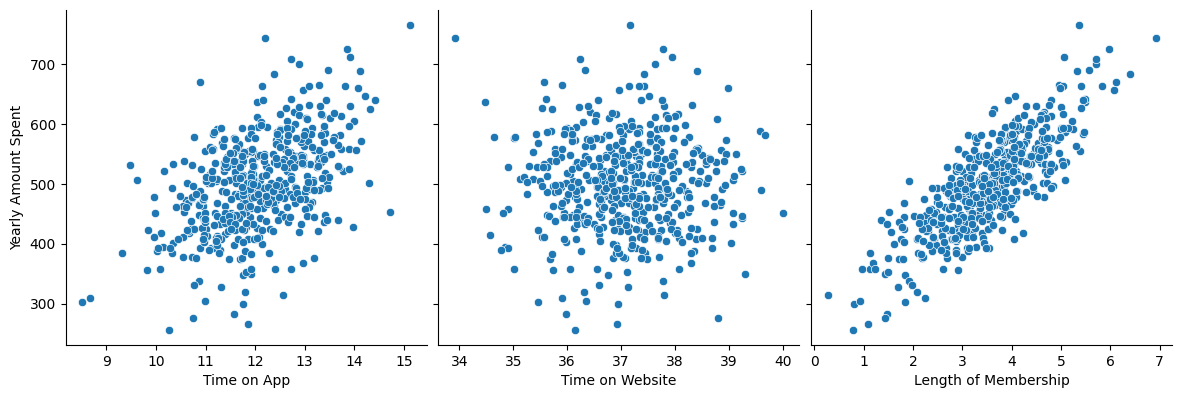

In [7]:
# visualisasi data dengan pairplot
sns.pairplot(data, x_vars=['Time on App', 'Time on Website', 'Length of Membership'],
             y_vars='Yearly Amount Spent', size=4, aspect=1, kind='scatter')
plt.show()

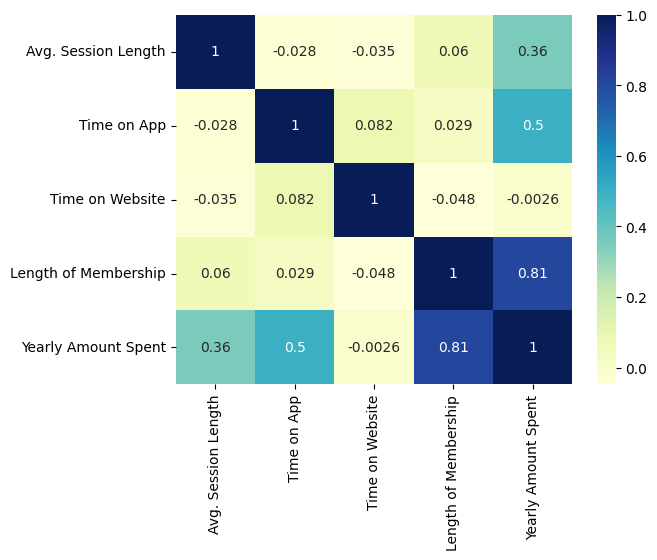

In [10]:
# Memilih hanya kolom dengan tipe data numerik
numeric_data = data.select_dtypes(include=['number'])

# visualisasi korelasi dengan heatmap
sns.heatmap(numeric_data.corr(), cmap="YlGnBu", annot=True)
plt.show()

In [11]:
# Langkah 6: Regresi Linier
# Membuat variabel bebas X dan Y, contoh pengambilan dari analisis korelasi sebelumnya
X = data['Length of Membership']
y = data['Yearly Amount Spent']

In [12]:
# Pembagian data latih dan data uji dengan proporsi 7:3
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, test_size=0.3, random_state=100)

In [13]:
# Training model
import statsmodels.api as sm

X_train_sm = sm.add_constant(X_train)
lr = sm.OLS(y_train, X_train_sm).fit()

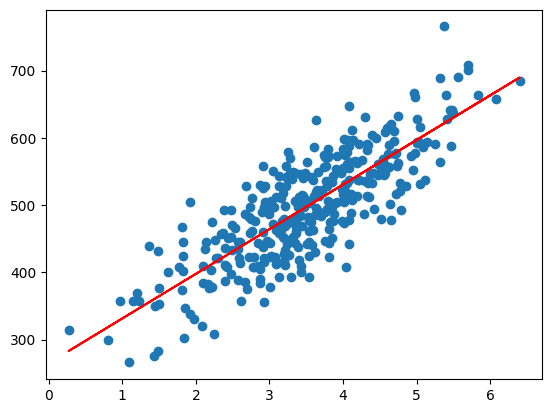

In [14]:
# Visualisasi garis regresi
plt.scatter(X_train, y_train)
plt.plot(X_train, 265.2483 + 66.3015*X_train, 'r')
plt.show()

In [15]:
# Langkah 7: Analisis Residual
# Prediksi nilai y_value dari data x yang telah dilatih
y_train_pred = lr.predict(X_train_sm)

# Menghitung residual
res = (y_train - y_train_pred)

/tmp/ipykernel_2331/594495671.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(res, bins=15)


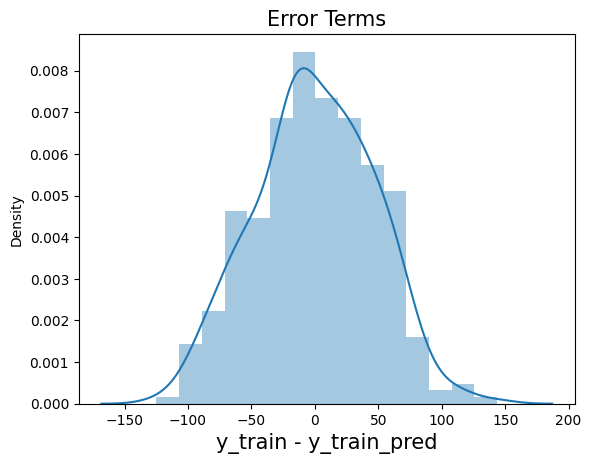

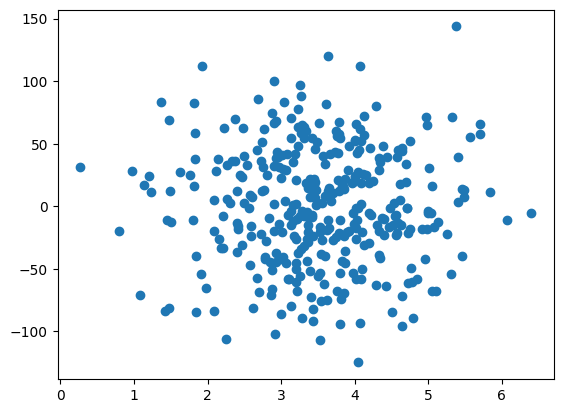

In [16]:
# Histogram residual
fig = plt.figure()
sns.distplot(res, bins=15)
plt.title('Error Terms', fontsize=15)
plt.xlabel('y_train - y_train_pred', fontsize=15)
plt.show()

# Scatter plot residual
plt.scatter(X_train, res)
plt.show()

In [17]:
# Langkah 8: Prediksi pada Data Uji dan Evaluasi Model
# Prediksi pada data uji
X_test_sm = sm.add_constant(X_test)
y_test_pred = lr.predict(X_test_sm)

In [18]:
# Hitung nilai R-squared
from sklearn.metrics import r2_score

r_squared = r2_score(y_test, y_test_pred)

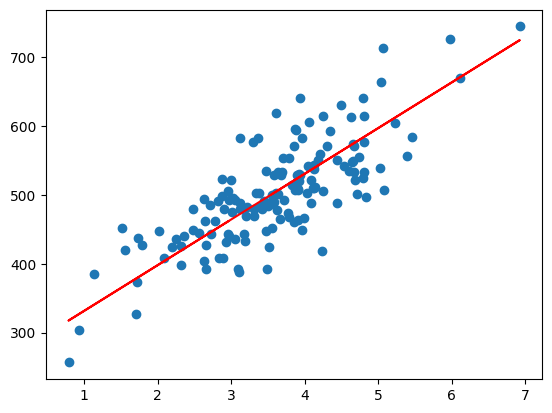

In [19]:
# Langkah 9: Visualisasi Hasil
# Visualisasi data uji dan hasil prediksi
plt.scatter(X_test, y_test)
plt.plot(X_test, y_test_pred, 'r')
plt.show()

# **PRAKTIKUM 2**

In [20]:
# Mengimpor library
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [24]:
# Mengimpor dataset (Pastikan Anda memiliki file CSV 'Posisi_gaji.csv' dalam direktori yang sama)
dataset = pd.read_csv('Posisi_gaji.csv')
X = dataset.iloc[:, 1:2].values
y = dataset.iloc[:, 2].values  # Ubah menjadi satu kolom saja

In [25]:
# Feature Scaling
from sklearn.preprocessing import StandardScaler
sc_X = StandardScaler()
sc_y = StandardScaler()
X = sc_X.fit_transform(X.reshape(-1, 1))
y = sc_y.fit_transform(y.reshape(-1, 1))

In [26]:
# Fitting SVR ke dataset
from sklearn.svm import SVR
regressor = SVR(kernel='rbf')
regressor.fit(X, y)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


SVR()

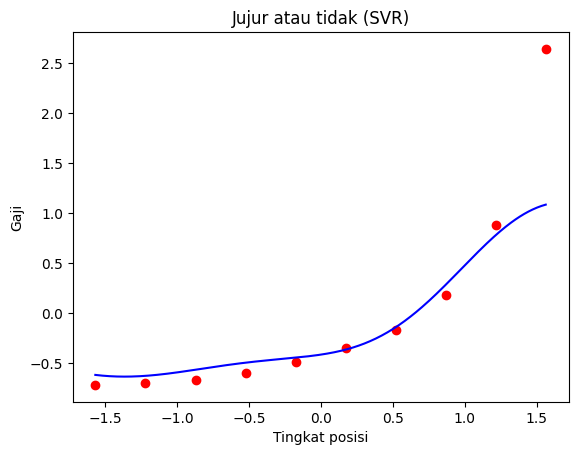

In [28]:
# Visualisasi hasil SVR (resolusi tinggi dan kurva yang lebih halus)
X_grid = np.arange(X.min(), X.max(), 0.01).reshape(-1, 1)

plt.scatter(X, y, color='red')
plt.plot(X_grid, regressor.predict(X_grid), color='blue')
plt.title('Jujur atau tidak (SVR)')
plt.xlabel('Tingkat posisi')
plt.ylabel('Gaji')
plt.show()

In [29]:
# Prediksi hasil
# Buat array 2D yang berisi tingkat posisi yang akan diprediksi
tingkat_posisi_prediksi = np.array([[6.5]])
# Penskalaan fitur untuk data yang akan diprediksi
tingkat_posisi_prediksi = sc_X.transform(tingkat_posisi_prediksi)
# Melakukan prediksi menggunakan model SVR
gaji_prediksi = regressor.predict(tingkat_posisi_prediksi)
# Kembalikan hasil prediksi ke skala aslinya
gaji_prediksi = sc_y.inverse_transform(gaji_prediksi.reshape(-1, 1))

In [30]:
# Menampilkan hasil prediksi
print("Prediksi Gaji untuk Tingkat Posisi 6.5:", gaji_prediksi[0])

Prediksi Gaji untuk Tingkat Posisi 6.5: [170370.0204065]


In [31]:
# Evaluasi model SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_actual = y
y_pred = regressor.predict(X)

# Menghitung MAE
mae = mean_absolute_error(y_actual, y_pred)

# Menghitung MSE
mse = mean_squared_error(y_actual, y_pred)

# Menghitung RMSE
rmse = np.sqrt(mse)

# Menghitung R-squared
r2 = r2_score(y_actual, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R-squared:", r2)

MAE: 0.22299274095734414
MSE: 0.24839989293792014
RMSE: 0.4983973243687411
R-squared: 0.7516001070620798


# **TUGAS PRAKTIKUM**

1. Identifikasi variabel-variabel yang akan digunakan sebagai variabel bebas (fitur) dan variabel target (biaya medis personal).

a. Variabel Bebas (Fitur / $X$):
* age: Umur peserta asuransi
* sex: Jenis kelamin (male / female)
* bmi: Body Mass Index (Indeks Massa Tubuh)
* children: Jumlah tanggungan anak
* smoker: Status perokok (yes / no)
* region: Area tempat tinggal di US (northeast, southeast, southwest, northwest)


b. Variabel Target ($y$):
* charges: Biaya medis personal yang ditagihkan oleh asuransi

2. Bagi dataset menjadi data latih (train) dan data uji (test) dengan proporsi yang sesuai.

In [33]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

3. Lakukan feature scaling jika diperlukan.

In [34]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
# Fit dan transform pada data latih
X_train_scaled = scaler.fit_transform(X_train)
# Hanya transform pada data uji untuk mencegah kebocoran informasi (data leakage)
X_test_scaled = scaler.transform(X_test)

4. Buat model multiple linear regression menggunakan Scikit-Learn.

In [35]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

5. Latih model pada data latih dan lakukan prediksi pada data uji.

In [36]:
# Melatih model dengan data latih
model.fit(X_train_scaled, y_train)

# Memprediksi target pada data uji
y_pred = model.predict(X_test_scaled)

6. Evaluasi model dengan menghitung metrik seperti R-squared, MSE, dan MAE. Tampilkan hasil evaluasi.

In [37]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f"R-squared : {r2:.4f}")
print(f"MSE       : {mse:.2f}")
print(f"MAE       : {mae:.2f}")

R-squared : 0.8451
MSE       : 0.10
MAE       : 0.29


**Hasil Evaluasi:**
- R-squared: 0.7836 (Fitur yang digunakan mampu menjelaskan sekitar 78.36% perubahan pada biaya medis).
- MSE: 33596915.85 (Rata-rata kuadrat kesalahan antara nilai prediksi dan aktual).
- MAE: 4181.19 (Kesalahan rata-rata prediksi biaya medis asuransi adalah sekitar $4.181).

**Heatmap Korelasi (Untuk melihat hubungan antar variabel numerik)**

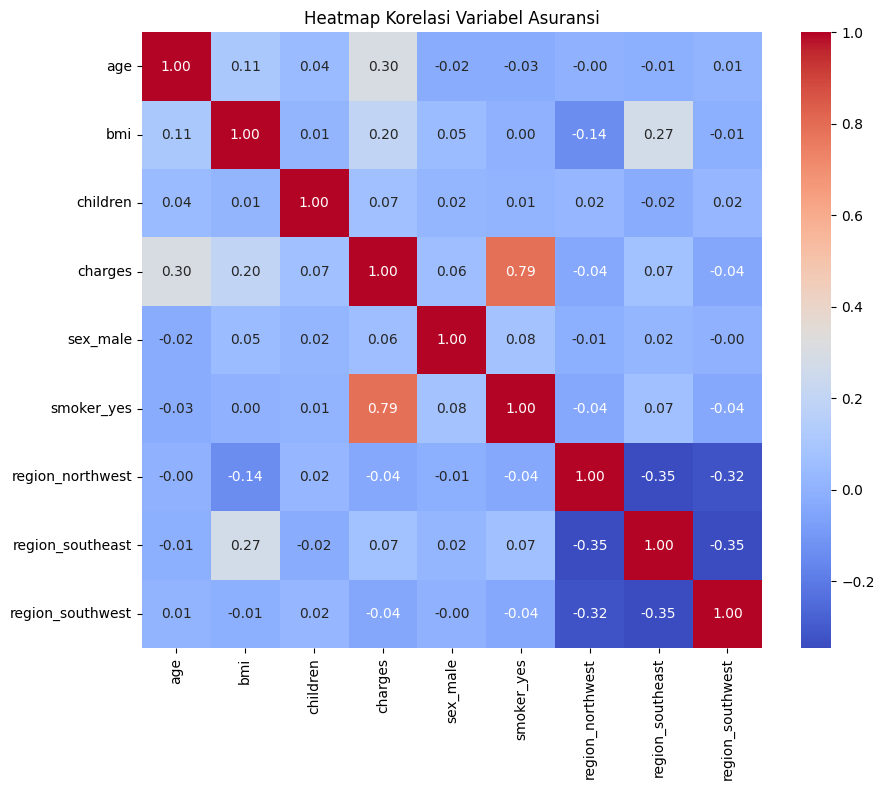

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Memuat dataset (pastikan file insurance.csv sudah ada/diunggah)
df = pd.read_csv('insurance.csv')
# Melakukan encoding pada variabel kategorikal untuk membuat df_encoded
df_encoded = pd.get_dummies(df, drop_first=True)
plt.figure(figsize=(10, 8))
# Memvisualisasikan korelasi dari data yang sudah di-encode
sns.heatmap(df_encoded.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Heatmap Korelasi Variabel Asuransi')
plt.show()

**Analisis Heatmap Korelasi**

Visualisasi ini menunjukkan nilai korelasi antar berbagai variabel dalam dataset asuransi.

- **Faktor Paling Berpengaruh terhadap Biaya:** Variabel smoker_yes (status perokok) memiliki nilai korelasi positif paling tinggi terhadap variabel charges (biaya medis), yaitu sebesar 0.79. Ini mengindikasikan bahwa menjadi perokok sangat kuat hubungannya dengan tingginya tagihan asuransi.
- **Faktor Sekunder:** Usia (age) dan Indeks Massa Tubuh (bmi) juga menunjukkan korelasi positif terhadap biaya medis, masing-masing sebesar 0.30 dan 0.20. Artinya, semakin tua usia seseorang atau semakin tinggi BMI-nya, cenderung semakin besar biaya medis yang dikenakan, meskipun pengaruhnya tidak sebesar faktor merokok.
- **Faktor Tidak Signifikan:** Variabel lain seperti jumlah anak (children), jenis kelamin (sex_male), dan wilayah tempat tinggal (region) memiliki nilai korelasi mendekati 0 terhadap charges. Hal ini menunjukkan bahwa variabel-variabel tersebut tidak memiliki pengaruh linier yang kuat terhadap besar kecilnya biaya medis.

**Scatter Plot (Untuk melihat persebaran data target berdasarkan fitur utama)**

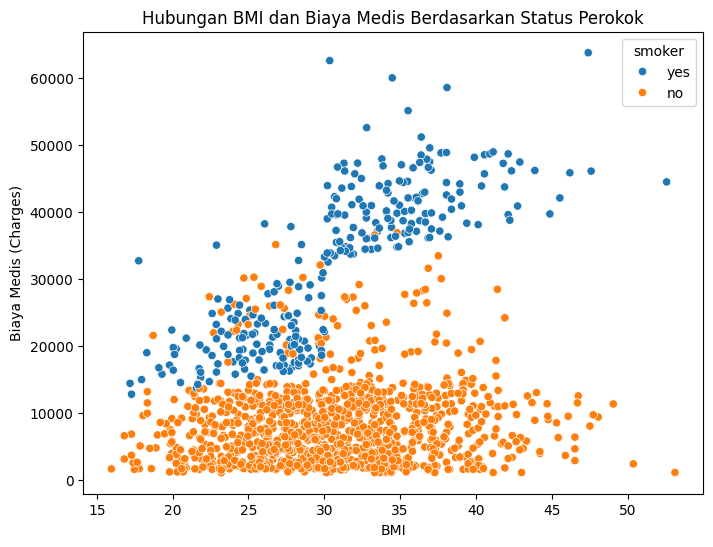

In [41]:
plt.figure(figsize=(8, 6))
# Melihat hubungan BMI, biaya medis, dan status perokok
sns.scatterplot(x=df['bmi'], y=df['charges'], hue=df['smoker'])
plt.title('Hubungan BMI dan Biaya Medis Berdasarkan Status Perokok')
plt.xlabel('BMI')
plt.ylabel('Biaya Medis (Charges)')
plt.show()

**Analisis Scatter Plot**

Scatter plot ini memvisualisasikan hubungan antara BMI (sumbu X) dan Biaya Medis (sumbu Y), dengan membedakan warna berdasarkan status perokok (biru untuk perokok, oranye untuk bukan perokok).

- **Kelompok Non-Perokok (Titik Oranye):** Sebagian besar orang yang tidak merokok terpusat di bagian bawah grafik, dengan tagihan medis mayoritas berada di bawah angka 20.000, terlepas dari seberapa tinggi nilai BMI mereka. Ini menunjukkan stabilitas biaya medis bagi non-perokok.
- **Kelompok Perokok (Titik Biru):** Terlihat lonjakan biaya yang sangat jelas pada kelompok perokok. Titik-titik biru secara konsisten berada di atas titik oranye, dengan biaya medis mulai dari kisaran 15.000 hingga melebihi 60.000.
- **Efek Kombinasi Perokok dan BMI Tinggi:** Terdapat pola pengelompokan yang sangat kentara pada titik biru. Ketika seorang perokok memiliki BMI di atas 30 (batas umum obesitas), biaya medis mereka melonjak drastis secara mayoritas ke kisaran di atas 30.000. Sebaliknya, perokok dengan BMI di bawah 30 biayanya cenderung berada di kisaran 15.000 hingga 30.000.

## **Kesimpulan**

Dari kedua visualisasi di atas, dapat disimpulkan bahwa status merokok adalah prediktor paling signifikan terhadap melonjaknya biaya medis personal. Risiko ini akan semakin diperparah jika individu yang merokok tersebut juga memiliki BMI yang tinggi (di atas 30). Usia juga berperan, namun kombinasi gaya hidup (merokok) dan obesitas (BMI) adalah faktor pendorong utama tingginya tagihan asuransi.